# Replicating the DOLAP 2026 experiment with open-weight models on Ollama

**What this notebook does.** It runs Strategy A (LLM only, no tools) on the **36 tasks of the published paper**
*On the Efficacy of Using LLMs for Context Driven Entity Augmentation in Property Graphs* (DOLAP 2026), with the
**9 published prompts**, **5 runs** per configuration and **both conditions** (without and with graph context),
using an open-weight model served locally by Ollama. It then scores the answers two ways and compares them with
the six proprietary models of the paper.

**Scope of this run: one model (Qwen3 4B Instruct), to check that the pipeline and the scoring are correct** before
running more models. Other models are added by running them (section 2); every table and chart picks them up.

| | Published run | This run |
|---|---|---|
| Tasks | 36 (9 airports × 4 H/G quadrants) | the same 36, imported unchanged from `test_results.csv` |
| Prompts | 9 (compact, zero, 1/3/5-shot, the same with CoT) | the same 9 files, unchanged |
| Input | `input: prop:value,…` + context | identical text without context; with context, the same procedure (a slice of 3–8 context entries) with a fixed seed, because the published slices were not saved |
| Runs | 5, then vote | 5, then the same vote |
| Models | Gemini 2.5 Pro/Flash, GPT-5/5 mini, Claude Sonnet/Haiku 4.5 | Qwen3 4B Instruct (Ollama, Q4_K_M); more can be added |
| Answers scored | voted answers | voted answers, same tolerance rules |

**Two scorings** (details in `src/evaluation/dolap.py`):

- **Published scoring** reproduces the paper's evaluation notebook: every property the model answered and that has a
  ground-truth value is compared (also properties that were not asked), unanswered properties are ignored, and F1 is
  computed with `y_true` all ones. Precision is therefore 1 by construction and **accuracy = recall = correct / answered**,
  F1 = 2·acc / (1 + acc). This is what Table 3 of the paper reports.
- **Standard scoring** (EVALUATION_SPEC): only the hidden properties H that have a ground truth. Each one is *correct*,
  *wrong* (a confident wrong value) or *abstained* (no value). Precision = correct / answered, recall = correct / |H|.
  This shows what the published scoring hides: abstentions and wrong answers.

In [1]:
from pathlib import Path
import json, os, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
from evaluation import dolap as D

TASKS = ROOT / "tasks/airports/dolap2026/tasks.csv"
RESULTS = ROOT / "results/airports/dolap2026/strategy_a"
CONFIG = ROOT / "configs/strategy_a_dolap2026.yaml"
NODE_VALUES = ROOT / "data/dolap2026/ground_truth.csv"
PUBLISHED = ROOT / "data/dolap2026/published_results"

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# Chart style: light surface, recessive axes, text in ink tokens (dataviz reference palette).
INK, INK2, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb", "#e6e5e0"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GOOD, CRITICAL, NEUTRAL = "#0ca30c", "#d03b3b", "#c9c8c2"
SEQ = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})
OLLAMA_ORDER = ["qwen3-4b-instruct", "nemotron-mini-4b", "llama3.2-1b"]
PUBLISHED_ORDER = ["Claude Sonnet 4.5", "Claude Haiku 4.5", "GPT-5", "GPT-5 Mini", "Gemini 2.5 Pro", "Gemini 2.5 Flash"]

## 1. The task set

The 36 published tasks, imported with
`tasks import-published --config configs/airports_dolap2026.yaml --no-graph --results data/dolap2026/test_results.csv --node-values data/dolap2026/ground_truth.csv`.
The recomputed difficulty must equal the published one: this checks that popularity, PageRank normalization and the
specificity formula are the ones of the paper.

In [2]:
tasks = D.load_tasks(TASKS)
view = tasks[["node_id", "node_stratum", "difficulty_prop", "H_names", "G_drawn", "size_G", "difficulty", "published_difficulty"]].copy()
view["G_drawn"] = view["G_drawn"].map(json.loads)
print(f"{len(tasks)} tasks, {tasks.node_id.nunique()} airports")
print("max |recomputed − published difficulty| =", float((tasks.difficulty - tasks.published_difficulty).abs().max()))
view.sort_values(["node_stratum", "node_id", "difficulty_prop"])

36 tasks, 9 airports
max |recomputed − published difficulty| = 7.105427357601002e-14


,node_id,node_stratum,difficulty_prop,H_names,G_drawn,size_G,difficulty,published_difficulty
0,PAKK,easy,easyeasy,"[location, source, dst]","[altitude, city]",2,6.578786,6.578786
1,PAKK,easy,easyhard,"[city, longitude, source]","[runwaysLength, runways, runwaysWidth]",3,7.776826,7.776826
2,PAKK,easy,hardeasy,"[runwaysLength, runways, iata]","[icao, tz_database_timezone, longitude]",3,7.659785,7.659785
3,PAKK,easy,hardhard,"[runways, iata, runwaysLength]","[runwaysWidth, commercial_flights]",1,16.721689,16.721689
8,VEGT,easy,easyeasy,"[distCity, altitude, city]","[name, latitude, source]",3,4.664484,4.664484
9,VEGT,easy,easyhard,"[altitude, city, name]","[runways, runwaysLength, iata]",3,5.247607,5.247607
10,VEGT,easy,hardeasy,"[runwaysLength, runwaysWidth, commercial_flights]","[tz_database_timezone, country, name]",3,8.277758,8.277758
11,VEGT,easy,hardhard,"[runwaysWidth, iata, runwaysLength]","[runways, commercial_flights]",1,11.445329,11.445329
4,YPPH,easy,easyeasy,"[source, name, latitude]","[icao, longitude, dst]",3,2.912722,2.912722
5,YPPH,easy,easyhard,"[timezone, name, latitude]","[runways, runwaysLength, runwaysWidth]",3,3.445549,3.445549


In [3]:
node_values = D.load_node_values(NODE_VALUES)
h_pairs = [(t.node_id, p) for t in tasks.itertuples() for p in t.H_names]
no_gt = pd.Series([p for n, p in h_pairs if p not in node_values.get(n, {})])
print(f"H properties: {len(h_pairs)}; without a ground-truth value (not scored, as in the paper): {len(no_gt)} -> "
      f"{no_gt.value_counts().to_dict()}")
print("Tasks by number of G values actually given (published: 'G' drawn may include properties the node lacks):",
      tasks["size_G"].value_counts().sort_index().to_dict())

H properties: 108; without a ground-truth value (not scored, as in the paper): 10 -> {'commercial_flights': 6, 'icao': 4}
Tasks by number of G values actually given (published: 'G' drawn may include properties the node lacks): {1: 4, 2: 10, 3: 22}


## 2. Running the models

One model takes about 1 hour on an Apple M4 (3,240 runs: 36 tasks × 18 variants × 5 runs). Every answer is cached,
so re-running is free; set `RUN = True` and list models in `MODELS` to run missing runs or new models
(ids from `configs/strategy_a_dolap2026.yaml`, e.g. `nemotron-mini-4b`, `llama3.2-1b`, `mistral-7b`).

In [4]:
RUN = False
MODELS = ["qwen3-4b-instruct"]
if RUN:
    for m in MODELS:
        subprocess.run(["strategy-a", "run", "--config", str(CONFIG), "--models", m], check=True)
mpath = RESULTS / "run_manifest.json"
manifest = json.loads(mpath.read_text()) if mpath.exists() else {"model_details": {}}  # written when a model's run ends
details = pd.DataFrame([{"model": k, "ollama tag": v.get("model"), "digest": str(v.get("digest"))[:12],
                         "params": (v.get("details") or {}).get("parameter_size"),
                         "quantization": (v.get("details") or {}).get("quantization_level"),
                         "Ollama": v.get("ollama_version")} for k, v in manifest["model_details"].items()])
details

,model,ollama tag,digest,params,quantization,Ollama
0,qwen3-4b-instruct,qwen3:4b-instruct,0edcdef34593,4.0B,Q4_K_M,0.33.3


## 3. Loading, voting and scoring

In [5]:
runs = D.load_runs(RESULTS)
models_present = [m for m in OLLAMA_ORDER if m in set(runs.model)]
done = runs.groupby("model").size().reindex(models_present)
print("runs per model:", done.to_dict(), "(complete = 3240)")
ollama_votes = D.voted_from_runs(runs, tasks)
published_votes = D.load_published_votes(PUBLISHED, tasks)
votes = pd.concat([ollama_votes, published_votes], ignore_index=True)
sp = D.score_published(votes, node_values)      # one row per compared property (paper's way)
ss = D.score_standard(votes, tasks, node_values) # one row per H property with a ground truth
print(f"configurations: {len(votes)}; compared properties (published scoring): {len(sp)}; scored H properties: {len(ss)}")
cov = D.coverage(votes)
cov[cov.airports < 9]

runs per model: {'qwen3-4b-instruct': 3240} (complete = 3240)


configurations: 4176; compared properties (published scoring): 8981; scored H properties: 11376


,source,model,context,airports,tasks,configurations
11,published,Gemini 2.5 Flash,True,4,16,144
13,published,Gemini 2.5 Pro,True,4,16,144


The table above lists the model × condition pairs that do **not** cover all 9 airports. In the published files, the
with-context runs of Gemini 2.5 Pro and Gemini 2.5 Flash only contain 4 airports (PAKK, VEGT, YPPH, ZUBJ: the three
most central ones and one of medium centrality). Their with-context results are computed on those airports only and
are not comparable with the other rows.

### 3.1 Check: the published scoring reproduces Table 3 of the paper

Table 3 lists the best configuration of each proprietary model. Recomputed here from the published voted answers:

In [6]:
pm = D.published_metrics(sp, ["source", "model", "context", "prompt"]).set_index(["model", "context", "prompt"])
table3 = [("Claude Sonnet 4.5", .80, .66, True, "few5"), ("Claude Haiku 4.5", .54, .37, True, "compact"),
          ("GPT-5", .67, .50, False, "3cot"), ("GPT-5 Mini", .57, .40, False, "few3"),
          ("Gemini 2.5 Pro", .65, .48, True, "5cot"), ("Gemini 2.5 Flash", .61, .44, True, "5cot")]
check = pd.DataFrame([{"model": m, "context": c, "prompt (from effort)": p, "paper F1": f, "paper recall": r,
                       "recomputed F1": pm.loc[(m, c, p), "f1"], "recomputed recall": pm.loc[(m, c, p), "recall"],
                       "compared": int(pm.loc[(m, c, p), "compared"])} for m, f, r, c, p in table3])
sonnet_best = pm.loc["Claude Sonnet 4.5"].sort_values("f1", ascending=False).head(3)
display(check.round(3))
print("Claude Sonnet 4.5, best configurations by published F1:")
sonnet_best.round(3)

,model,context,prompt (from effort),paper F1,paper recall,recomputed F1,recomputed recall,compared
0,Claude Sonnet 4.5,True,few5,0.80,0.66,0.720,0.563,119
1,Claude Haiku 4.5,True,compact,0.54,0.37,0.545,0.375,40
2,GPT-5,False,3cot,0.67,0.50,0.674,0.508,59
3,GPT-5 Mini,False,few3,0.57,0.40,0.576,0.404,47
4,Gemini 2.5 Pro,True,5cot,0.65,0.48,0.656,0.488,43
5,Gemini 2.5 Flash,True,5cot,0.61,0.44,0.613,0.442,52


Claude Sonnet 4.5, best configurations by published F1:


source  compared  accuracy  precision  recall     f1
context prompt                                                         
True    1cot    published       3.0     0.667        1.0   0.667  0.800
        5cot    published      37.0     0.622        1.0   0.622  0.767
False   few5    published     114.0     0.614        1.0   0.614  0.761

**The replication of the scoring works, and it surfaces three problems in the published results.**

- **Five of the six Table 3 rows are reproduced exactly** (GPT-5, GPT-5 Mini, Gemini 2.5 Pro and Flash, Claude Haiku), so the tasks, the prompt mapping (p0 = compact … p8 = 1cot), the vote and the tolerance are the paper's.
- **Claude Sonnet 4.5's row (F1 0.80, recall 0.66) is the 1-shot + CoT configuration with context, which rests on 3 compared properties.** The 5-shot configuration that the effort column (414 tokens) points to gives F1 0.72 over 119 properties. Either the effort column is wrong or the best configuration was picked from 3 answers; both should be corrected.
- **The with-context Gemini results cover 4 of the 9 airports** (the three most central and one medium), so they are not comparable with the other rows (table above).
- A fourth point to check on your side, not visible in the scores: `gpt_batch_requests.jsonl`, whose request ids start with `context_gpt_mini`, contains inputs **without** context (`[NO_CONTEXT_ADDED]`). If those were the requests sent, the GPT-5 Mini with-context run was actually a second no-context run.

### 3.2 Format compliance

The published prompts ask for CSV `property,value` only. A run whose answer has no CSV is a format failure: the paper
counted only answers in the requested structure, so these runs contribute nothing (no repair call here either).

In [7]:
comp = runs.assign(ok=runs.status.eq("ok")).groupby(["model", "variant"]).ok.mean().unstack()
order_cols = [p for p in D.PROMPT_ORDER] + [p + "_ctx" for p in D.PROMPT_ORDER]
comp = comp.reindex(index=models_present, columns=[c for c in order_cols if c in comp.columns])
print("Share of runs answered in CSV format:")
comp.round(2)

Share of runs answered in CSV format:


variant,compact,zero,few1,few3,few5,zerocot,1cot,3cot,5cot,compact_ctx,zero_ctx,few1_ctx,few3_ctx,few5_ctx,zerocot_ctx,1cot_ctx,3cot_ctx,5cot_ctx
model,,,,,,,,,,,,,,,,,,
qwen3-4b-instruct,1.0,1.0,0.99,1.0,1.0,1.0,1.0,1.0,0.99,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.99


## 4. Results

### 4.1 Best configuration per model (Table 3, extended)

For each model and condition: the prompt with the best **published** F1, as in the paper, and next to it the
**standard** metrics of that same configuration. `compared` is the number of answered properties the published
F1 rests on.

In [8]:
std = D.standard_metrics(ss, ["source", "model", "context", "prompt"])
both = D.published_metrics(sp, ["source", "model", "context", "prompt"]).merge(
    std, on=["source", "model", "context", "prompt"], suffixes=("_pub", "_std"))
best = (both.sort_values(["f1_pub", "compared"], ascending=False)
            .groupby(["model", "context"]).head(1)
            .sort_values(["source", "model", "context"]))
cols = ["source", "model", "context", "prompt", "compared", "accuracy", "f1_pub",
        "properties", "precision_std", "recall_std", "f1_std", "abstention_rate", "error_rate"]
best_tbl = best[cols].rename(columns={"accuracy": "pub acc (=recall)", "f1_pub": "pub F1", "precision_std": "precision",
                                      "recall_std": "recall", "f1_std": "F1"})
best_tbl.round(3)

,source,model,context,prompt,compared,pub acc (=recall),pub F1,properties,precision,recall,F1,abstention_rate,error_rate
4,ollama,qwen3-4b-instruct,False,few1,93.0,0.312,0.475,98.0,0.152,0.071,0.097,0.531,0.398
13,ollama,qwen3-4b-instruct,True,few1,158.0,0.424,0.596,98.0,0.212,0.112,0.147,0.469,0.418
18,published,Claude Haiku 4.5,False,3cot,29.0,0.379,0.550,98.0,0.421,0.082,0.137,0.806,0.112
28,published,Claude Haiku 4.5,True,compact,40.0,0.375,0.545,98.0,0.326,0.143,0.199,0.561,0.296
40,published,Claude Sonnet 4.5,False,few5,114.0,0.614,0.761,98.0,0.531,0.347,0.420,0.347,0.306
42,published,Claude Sonnet 4.5,True,1cot,3.0,0.667,0.800,98.0,0.667,0.020,0.040,0.969,0.010
51,published,GPT-5,False,3cot,59.0,0.508,0.674,98.0,0.538,0.357,0.429,0.337,0.306
61,published,GPT-5,True,5cot,59.0,0.475,0.644,98.0,0.508,0.337,0.405,0.337,0.327
70,published,GPT-5 Mini,False,5cot,49.0,0.429,0.600,98.0,0.423,0.224,0.293,0.469,0.306
79,published,GPT-5 Mini,True,5cot,71.0,0.352,0.521,98.0,0.367,0.296,0.328,0.194,0.510


### 4.2 Overall, over all 9 prompts

Choosing the best prompt after seeing the results favours models with more variance (and the best Sonnet configuration
rests on 3 answers). The fairer summary averages over all prompts: micro-averaged standard metrics over every scored
H property, with a 95% bootstrap interval over the 36 tasks.

In [9]:
rng = np.random.default_rng(0)
def boot_f1(g, n=1000):
    per_task = g.groupby("task_id").outcome.value_counts().unstack(fill_value=0).reindex(columns=["correct", "wrong", "abstained"], fill_value=0)
    arr = per_task.to_numpy()
    out = []
    for _ in range(n):
        c, w, a = arr[rng.integers(0, len(arr), len(arr))].sum(0)
        p = c / (c + w) if c + w else 0.0
        r = c / (c + w + a)
        out.append(2 * p * r / (p + r) if c else 0.0)
    return np.percentile(out, [2.5, 97.5])

overall = D.standard_metrics(ss, ["source", "model", "context"])
ci = ss.groupby(["model", "context"]).apply(boot_f1, include_groups=False)
overall["F1 95% CI"] = [f"[{ci[(m, c)][0]:.2f}, {ci[(m, c)][1]:.2f}]" for m, c in zip(overall.model, overall.context)]
pub_overall = D.published_metrics(sp, ["model", "context"])[["model", "context", "accuracy", "compared"]]
overall = overall.merge(pub_overall, on=["model", "context"]).rename(columns={"accuracy": "pub accuracy"})
overall = overall.sort_values(["source", "context", "f1"], ascending=[True, True, False])
overall[["source", "model", "context", "properties", "correct", "wrong", "abstained", "precision", "recall", "f1",
         "F1 95% CI", "abstention_rate", "error_rate", "pub accuracy", "compared"]].round(3)

,source,model,context,properties,correct,wrong,abstained,precision,recall,f1,F1 95% CI,abstention_rate,error_rate,pub accuracy,compared
0,ollama,qwen3-4b-instruct,False,882.0,47.0,433.0,402.0,0.098,0.053,0.069,"[0.04, 0.10]",0.456,0.491,0.233,780.0
1,ollama,qwen3-4b-instruct,True,882.0,109.0,440.0,333.0,0.199,0.124,0.152,"[0.09, 0.22]",0.378,0.499,0.365,1182.0
6,published,GPT-5,False,882.0,300.0,283.0,299.0,0.515,0.340,0.410,"[0.31, 0.50]",0.339,0.321,0.471,529.0
12,published,Gemini 2.5 Pro,False,882.0,262.0,522.0,98.0,0.334,0.297,0.315,"[0.22, 0.41]",0.111,0.592,0.318,825.0
8,published,GPT-5 Mini,False,882.0,194.0,307.0,381.0,0.387,0.220,0.281,"[0.19, 0.37]",0.432,0.348,0.373,496.0
10,published,Gemini 2.5 Flash,False,882.0,187.0,403.0,292.0,0.317,0.212,0.254,"[0.17, 0.35]",0.331,0.457,0.384,805.0
4,published,Claude Sonnet 4.5,False,882.0,133.0,187.0,562.0,0.416,0.151,0.221,"[0.16, 0.29]",0.637,0.212,0.494,494.0
2,published,Claude Haiku 4.5,False,882.0,87.0,304.0,491.0,0.223,0.099,0.137,"[0.08, 0.20]",0.557,0.345,0.224,554.0
13,published,Gemini 2.5 Pro,True,396.0,149.0,214.0,33.0,0.410,0.376,0.393,"[0.22, 0.55]",0.083,0.540,0.433,374.0
7,published,GPT-5,True,882.0,288.0,301.0,293.0,0.489,0.327,0.392,"[0.29, 0.49]",0.332,0.341,0.444,532.0


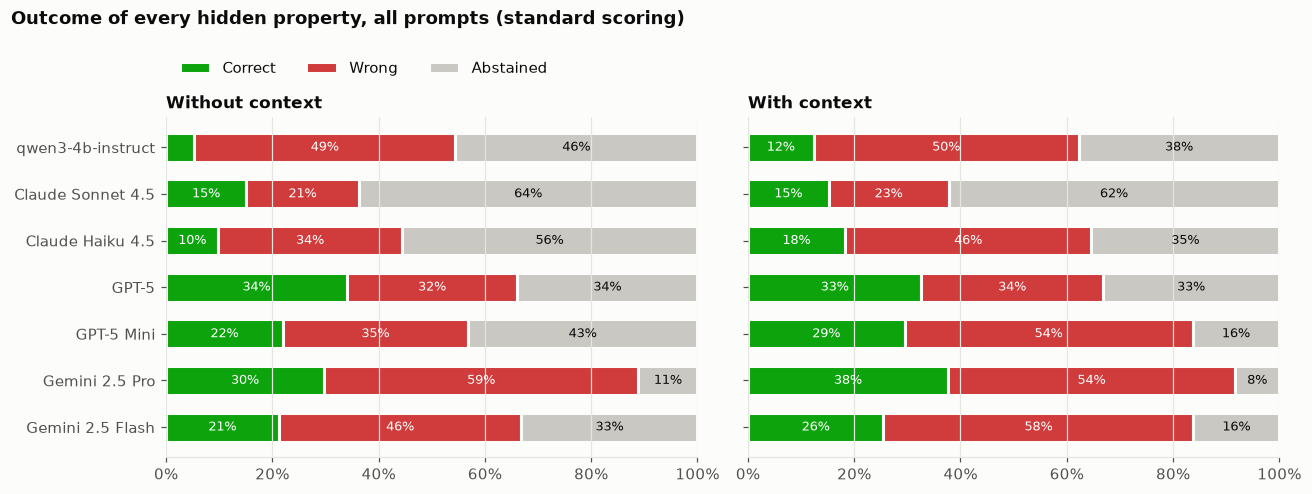

In [10]:
def model_order(df):
    present = set(df.model)
    return [m for m in OLLAMA_ORDER + PUBLISHED_ORDER if m in present]

def outcome_chart(df, title):
    order = model_order(df)
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.42 * len(order) + 1.6), sharey=True)
    for ax, ctx in zip(axes, [False, True]):
        sub = df[df.context == ctx].set_index("model").reindex(order)
        n = sub["properties"].to_numpy(float)
        left = np.zeros(len(order))
        for col, color, label in [("correct", GOOD, "Correct"), ("wrong", CRITICAL, "Wrong"), ("abstained", NEUTRAL, "Abstained")]:
            share = np.nan_to_num(sub[col].to_numpy(float) / n)
            ax.barh(range(len(order)), share, left=left, color=color, height=0.62, edgecolor=SURFACE, linewidth=2, label=label)
            for i, (l, s) in enumerate(zip(left, share)):
                if s >= 0.08:
                    ax.text(l + s / 2, i, f"{s:.0%}", ha="center", va="center", fontsize=8.5,
                            color="white" if col != "abstained" else INK)
            left += share
        ax.set_title("With context" if ctx else "Without context", fontsize=11)
        ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.grid(axis="y", visible=False)
        ax.set_yticks(range(len(order)), order)
    axes[0].invert_yaxis()  # shared y: flip once, first model on top
    axes[0].legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.08))
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()

outcome_chart(overall, "Outcome of every hidden property, all prompts (standard scoring)")

**What counts as wrong.** The paper's tolerance (token overlap ≥ 0.75, relative similarity ≥ 0.75, 10 km for
coordinates) is applied as published. Most wrong answers are genuinely wrong (another airport, another code), but a
part are unit or format mismatches: runway lengths in metres against feet, `distCity` in km against metres,
coordinates written `lat/lon` against `POINT(lon,lat)`. They affect every model alike. A sample:

In [11]:
w = ss[ss.outcome == "wrong"].merge(votes[["model", "variant", "task_id", "answer"]], on=["model", "variant", "task_id"])
w["predicted"] = [a.get(p) for a, p in zip(w.answer, w.property)]
w["ground truth"] = [node_values[n].get(p) for n, p in zip(w.node, w.property)]
print("Wrong answers by property:", w.property.value_counts().head(8).to_dict())
w[w.property.isin(["runwaysLength", "distCity", "altitude", "location", "iata", "name"])].drop_duplicates(["property", "node"])     [["model", "node", "property", "predicted", "ground truth"]].head(14)

Wrong answers by property: {'runwaysLength': 676, 'iata': 490, 'runwaysWidth': 460, 'timezone': 456, 'altitude': 413, 'runways': 380, 'name': 305, 'source': 300}


,model,node,property,predicted,ground truth
2,qwen3-4b-instruct,HESN,distCity,Paris,15878.396171
6,qwen3-4b-instruct,VEGT,distCity,28.0,17058.108938
7,qwen3-4b-instruct,VEGT,altitude,1369.0,162.0
11,qwen3-4b-instruct,KEUG,iata,KEUG,EUG
12,qwen3-4b-instruct,KEUG,runwaysLength,"3000 ft, 4000 ft",6412.333333
15,qwen3-4b-instruct,VEGT,name,Gau Airport,Lokpriya Gopinath Bordoloi International Airport
17,qwen3-4b-instruct,KEUG,name,Paris-Charles de Gaulle Airport,Mahlon Sweet Field
18,qwen3-4b-instruct,YPPH,runwaysLength,2450.0,9197.5
19,qwen3-4b-instruct,YPPH,iata,YPPH,PER
22,qwen3-4b-instruct,ENSD,name,Tromsø Airport,Sandane Airport (Anda)


**Qwen3 4B is far below every proprietary model, and the gap is in wrong answers, not abstentions.**

- **Standard F1: 0.07 without context (95% CI 0.04–0.10) and 0.15 with context (0.09–0.22).** The best proprietary model, GPT-5, reaches 0.41 and 0.39; the weakest, Claude Haiku, 0.14 and 0.22.
- **About half of the hidden properties are answered wrongly** (error rate 0.49 and 0.50), and Qwen is right on only about 1 answer in 10 (precision 0.10) without context and 1 in 5 (0.20) with it. It does not abstain more than the others (0.46 and 0.38); it guesses.
- **The wrong answers are genuine, not scoring artifacts**: a hand check of a random sample shows other airports (Paris-CDG for Eugene, Tromsø for Sandane), ICAO codes given as IATA codes (`KEUG` for `EUG`), and implausible numbers. The scorer behaves as intended; three runs out of 3,240 were degenerate repetition loops (`truncated`), and their parseable values were kept.
- **The published scoring hides this.** Under it, Qwen's best configuration (1-shot with context) gets F1 0.60, in the range of the proprietary models (0.52–0.80), because that F1 ignores abstentions, sets precision to 1 by construction, and counts every property the model returned, asked or not. Qwen echoed 277 values given in the input (92% count as correct) and added 725 unasked properties; on the properties actually asked its accuracy is 0.16, against 0.37 under the published scoring. The proprietary models gain from this too (Claude Sonnet: 396 unasked properties, 71% correct). **The standard scoring should be the headline metric of the new paper.**
- With the standard scoring, the paper's statement that "precision steadily equals 1" does not hold: precision is 0.22–0.52 for the proprietary models.

### 4.3 Prompts and effort

Standard F1 per model and prompt (rows: models; columns: prompts ordered by prompt formulation effort). PFE is the
number of tokens of the prompt text (cl100k_base), as in Figure 1 of the paper.

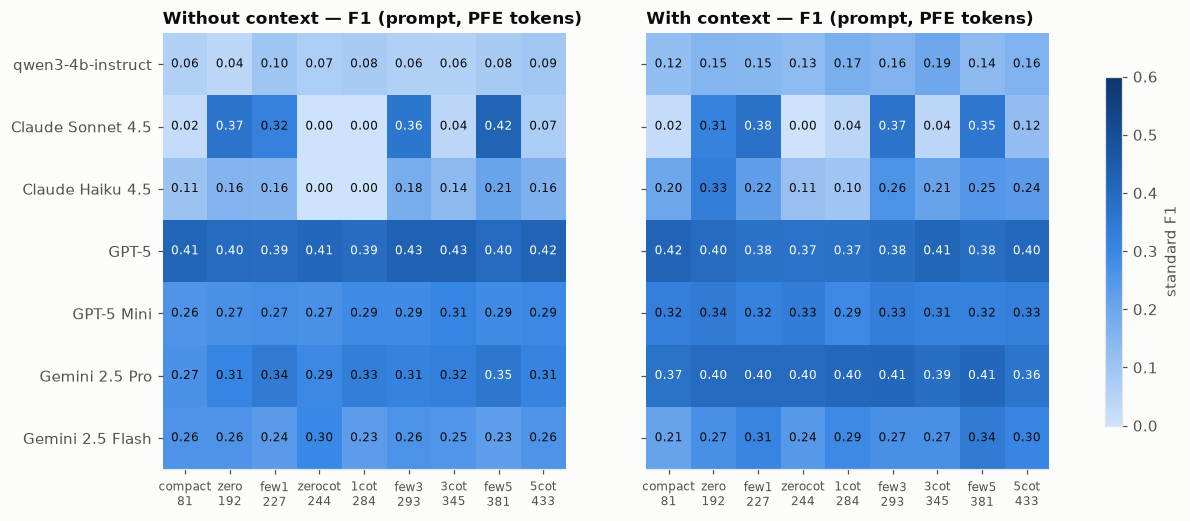

In [12]:
from strategy_a.config import load_config
from strategy_a.runner import Runner
_r = Runner(load_config(CONFIG), connect=False, log=lambda m: None); _r.prepare()
pfe = pd.Series({v: n for (v, m), n in _r.pfe.items()})  # same for every model with cl100k_base
by_prompt = D.standard_metrics(ss, ["model", "context", "prompt"])
prompts_by_effort = sorted(D.PROMPT_ORDER, key=lambda p: pfe.get(p, 0))
fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * len(model_order(by_prompt)) + 2), sharey=True)
order = model_order(by_prompt)
for ax, ctx in zip(axes, [False, True]):
    grid = by_prompt[by_prompt.context == ctx].pivot(index="model", columns="prompt", values="f1").reindex(index=order, columns=prompts_by_effort)
    im = ax.imshow(grid.to_numpy(float), cmap=SEQ, vmin=0, vmax=max(0.6, np.nanmax(by_prompt.f1)), aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.35 else INK)
    ax.set_xticks(range(len(prompts_by_effort)), [f"{p}\n{int(pfe.get(p, 0))}" for p in prompts_by_effort], fontsize=8)
    ax.set_yticks(range(len(order)), order); ax.grid(False)
    ax.set_title(("With" if ctx else "Without") + " context — F1 (prompt, PFE tokens)", fontsize=11)
fig.colorbar(im, ax=axes, shrink=0.8, label="standard F1")
plt.show()

In [13]:
eff = by_prompt.assign(pfe=by_prompt.prompt.map(pfe))
corr = eff.groupby(["model", "context"]).apply(lambda g: g[["pfe", "f1"]].corr(method="spearman").iloc[0, 1], include_groups=False)
print("Spearman correlation between prompt effort (PFE) and F1, per model and condition:")
corr.unstack().reindex(model_order(eff)).round(2)

Spearman correlation between prompt effort (PFE) and F1, per model and condition:


context,False,True
model,,
qwen3-4b-instruct,0.25,0.53
Claude Sonnet 4.5,0.21,0.17
Claude Haiku 4.5,0.49,0.17
GPT-5,0.41,0.03
GPT-5 Mini,0.85,-0.32
Gemini 2.5 Pro,0.48,0.10
Gemini 2.5 Flash,-0.16,0.56


**Prompt effort buys little and inconsistently.**

- For Qwen, F1 rises weakly with effort (Spearman 0.25 without context, 0.53 with context), and the 1-shot prompt is its best one in both conditions.
- Across the proprietary models the correlation ranges from −0.32 to 0.85; GPT-5 is almost flat across the 9 prompts (F1 0.33–0.38), while Claude Sonnet collapses to 0 on compact, zero-shot CoT and 1-shot CoT (it abstains on everything) and reaches 0.33–0.37 on zero-shot and the 3/5-shot prompts.
- So, as in the paper, the effect of effort is model dependent; with 36 tasks, differences of a few points between prompts are within noise.

### 4.4 Does context help?

Paired comparison per model: the same tasks and prompts, with and without context (standard scoring, all prompts).

In [14]:
ctx_cmp = overall.pivot(index="model", columns="context", values=["f1", "recall", "abstention_rate", "error_rate"])
ctx_delta = pd.DataFrame({m: ctx_cmp[m][True] - ctx_cmp[m][False] for m in ["f1", "recall", "abstention_rate", "error_rate"]})
ctx_delta = ctx_delta.reindex(model_order(overall))
print("With context minus without context (positive F1 = context helps):")
ctx_delta.round(3)

With context minus without context (positive F1 = context helps):


,f1,recall,abstention_rate,error_rate
model,,,,
qwen3-4b-instruct,0.083,0.070,-0.078,0.008
Claude Sonnet 4.5,-0.001,0.001,-0.015,0.014
Claude Haiku 4.5,0.085,0.084,-0.203,0.119
GPT-5,-0.018,-0.014,-0.007,0.020
GPT-5 Mini,0.040,0.075,-0.269,0.194
Gemini 2.5 Pro,0.078,0.079,-0.028,-0.051
Gemini 2.5 Flash,0.023,0.043,-0.169,0.126


**Context helps Qwen, mostly by making it answer more.**

- With context, Qwen's F1 rises by 0.08 (recall +0.07, abstention −0.08, error rate unchanged), and runs agree more (78% of hidden properties identical across the 5 runs, against 67%).
- Among the published models, context helps Claude Haiku (+0.09) and GPT-5 Mini (+0.04, but with a much higher error rate, +0.19), and does nothing for GPT-5 and Claude Sonnet. Gemini's gains are on 4 airports only.
- Note that the with-context inputs here use the published procedure (a random slice of 3–8 context entries, now seeded), not the exact published slices, which were not saved.

### 4.5 Difficulty

The paper's claim: accuracy falls with difficulty (H/G quadrants, node centrality), and context helps most for the
hardest quadrant. First by quadrant and node stratum, then the correlation between the difficulty score and the
F1 of each task.

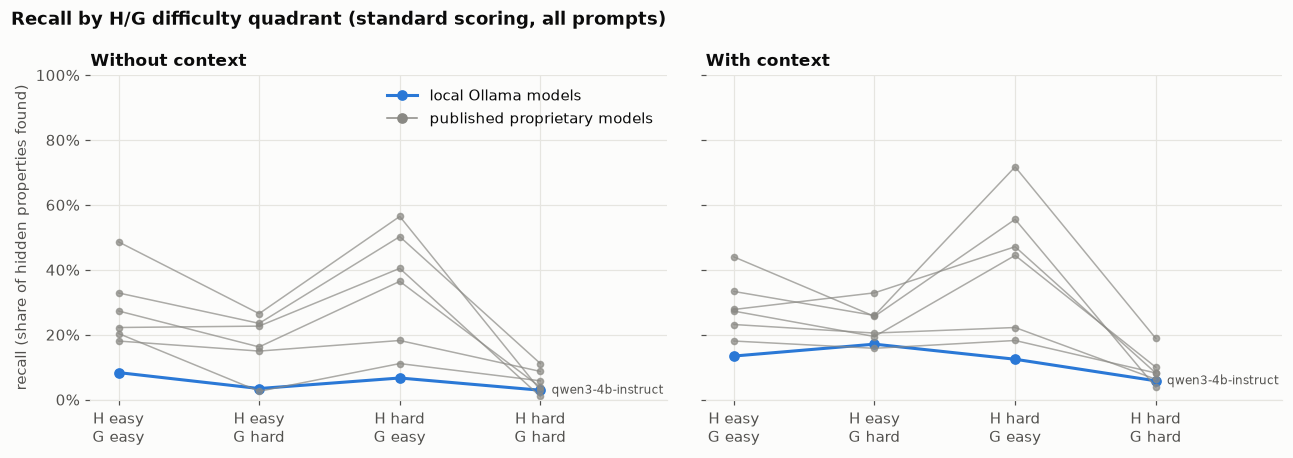

In [15]:
quad = D.standard_metrics(ss, ["source", "model", "context", "difficulty_prop"])
order = model_order(quad)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, ctx in zip(axes, [False, True]):
    sub = quad[quad.context == ctx]
    for m in order:
        s = sub[sub.model == m].set_index("difficulty_prop").reindex(D.QUADRANTS)
        is_local = m in OLLAMA_ORDER
        ax.plot(range(4), s.recall, marker="o", markersize=6 if is_local else 4, linewidth=2 if is_local else 1,
                color=BLUE if is_local else MUTED, alpha=1 if is_local else 0.7)
        last = s.recall.dropna()
        if len(last) and is_local:
            ax.text(3.08, last.iloc[-1], m, fontsize=8, va="center", color=INK2)
    ax.set_xticks(range(4), ["H easy\nG easy", "H easy\nG hard", "H hard\nG easy", "H hard\nG hard"])
    ax.set_xlim(-0.2, 3.9); ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title("With context" if ctx else "Without context", fontsize=11)
axes[0].set_ylabel("recall (share of hidden properties found)")
axes[0].plot([], [], color=BLUE, lw=2, marker="o", label="local Ollama models")
axes[0].plot([], [], color=MUTED, lw=1, marker="o", label="published proprietary models")
axes[0].legend(loc="upper right")
fig.suptitle("Recall by H/G difficulty quadrant (standard scoring, all prompts)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

In [16]:
qt = quad.pivot_table(index=["model", "context"], columns="difficulty_prop", values="recall").reindex(columns=D.QUADRANTS)
print("Recall by quadrant (table view of the chart):")
qt.reindex(model_order(quad), level=0).round(2)

Recall by quadrant (table view of the chart):


difficulty_prop            easyeasy  easyhard  hardeasy  hardhard
model             context                                        
qwen3-4b-instruct False        0.08      0.03      0.07      0.03
                  True         0.13      0.17      0.12      0.06
Claude Sonnet 4.5 False        0.18      0.15      0.18      0.09
                  True         0.18      0.16      0.18      0.08
Claude Haiku 4.5  False        0.20      0.03      0.11      0.06
                  True         0.23      0.21      0.22      0.06
GPT-5             False        0.49      0.26      0.56      0.03
                  True         0.44      0.26      0.56      0.04
GPT-5 Mini        False        0.22      0.23      0.40      0.01
                  True         0.28      0.33      0.47      0.08
Gemini 2.5 Pro    False        0.33      0.24      0.50      0.11
                  True         0.33      0.26      0.72      0.19
Gemini 2.5 Flash  False        0.27      0.16      0.36      0.04
                  True         0.27      0.19      0.44      0.10

In [17]:
strata = D.standard_metrics(ss, ["model", "context", "node_stratum"]).pivot_table(index=["model", "context"], columns="node_stratum", values="recall")
print("Recall by node centrality stratum (easy = most central airports):")
strata.reindex(columns=["easy", "medium", "hard"]).reindex(model_order(strata.reset_index()), level=0).round(2)

Recall by node centrality stratum (easy = most central airports):


node_stratum               easy  medium  hard
model             context                    
qwen3-4b-instruct False    0.06    0.06  0.03
                  True     0.09    0.13  0.15
Claude Sonnet 4.5 False    0.16    0.17  0.12
                  True     0.16    0.16  0.14
Claude Haiku 4.5  False    0.08    0.14  0.08
                  True     0.15    0.25  0.15
GPT-5             False    0.32    0.39  0.31
                  True     0.31    0.39  0.28
GPT-5 Mini        False    0.21    0.26  0.19
                  True     0.24    0.38  0.27
Gemini 2.5 Pro    False    0.31    0.30  0.28
                  True     0.40    0.31   NaN
Gemini 2.5 Flash  False    0.20    0.24  0.20
                  True     0.27    0.21   NaN

In [18]:
tf = D.task_f1(ss)
rho = tf.groupby(["model", "context"]).apply(lambda g: g[["difficulty", "f1"]].corr(method="spearman").iloc[0, 1], include_groups=False)
print("Spearman correlation between task difficulty and task F1 (negative = harder tasks are answered worse):")
rho.unstack().reindex(model_order(tf)).round(2)

Spearman correlation between task difficulty and task F1 (negative = harder tasks are answered worse):


context,False,True
model,,
qwen3-4b-instruct,-0.18,-0.02
Claude Sonnet 4.5,-0.11,-0.07
Claude Haiku 4.5,-0.11,-0.15
GPT-5,-0.22,-0.21
GPT-5 Mini,-0.21,-0.11
Gemini 2.5 Pro,-0.20,-0.26
Gemini 2.5 Flash,-0.15,-0.38


**The difficulty metric predicts little, and the quadrants are not ordered as the paper assumes.**

- The correlation between the difficulty score and task F1 is negative but weak for every model (Spearman −0.02 to −0.38); with 36 tasks from 9 airports, most of these are not distinguishable from zero.
- **H-hard / G-easy is the easiest quadrant for the strong models** (GPT-5 recall 0.56, Gemini 2.5 Pro 0.50), not the third hardest. The "hard" H properties are mostly `iata` and runway counts, which follow directly once the airport is identified, and an "easy" G (name, ICAO, city) identifies it. H-hard / G-hard is the hardest for everyone (recall ≤ 0.11 without context).
- **What drives success is whether G identifies the airport.** For Qwen without context, recall is 0.08 when G contains a name, code or city, and 0.02 when it does not.
- **Popularity is not findability.** Several "easy" properties (present on ≥ 80% of airports) are dataset artifacts no model can know: `source` (always "OurAirports"), `dst` (a one-letter DST rule code), `timezone` (a UTC offset like `8`, where models answer `Asia/Shanghai`) and `distCity` (a computed distance in metres). Across all models their recall is 0–10%. The new paper's difficulty definition should account for this, for example by excluding derived properties.
- Node centrality shows no consistent effect: recall is similar across the three strata for most models, and with context Qwen does best on the least central airports (0.15 against 0.09).

### 4.6 Stability across the 5 runs

Before voting: for each hidden property, do the 5 runs give the same answer (the same normalized value, or all
abstain)? Low agreement means the vote matters a lot, and the result of one run is not reproducible.

In [19]:
h_names = tasks.set_index("task_id").H_names.to_dict()
def agreement(g):
    vals = []
    for prop in h_names[g.name[2]]:
        answers = [D.coerce((a or {}).get(prop)) for a in g.answer]
        norm = [None if v is None else (round(v, 1) if isinstance(v, float) else " ".join(D.normalize_tokens(v))) for v in answers]
        vals.append(len(set(norm)) == 1)
    return np.mean(vals)
stab = runs.groupby(["model", "context_flag" if False else "variant", "task_id"]).apply(agreement, include_groups=False).rename("agree").reset_index()
stab["context"] = stab.variant.str.endswith("_ctx")
print("Share of hidden properties on which all 5 runs agree:")
stab.groupby(["model", "context"]).agree.mean().unstack().reindex(models_present).round(2)

Share of hidden properties on which all 5 runs agree:


context,False,True
model,,
qwen3-4b-instruct,0.67,0.78


### 4.7 Cost and sustainability

Tokens, latency and energy over all runs of each local model. **The energy figures are estimates and undercount**:
on this Apple M4, CodeCarbon finds no GPU it can measure and estimates CPU and RAM power from load, while Ollama runs
on the Apple GPU (every value is flagged `estimated: true, gpu_measured: false` in `runs.jsonl`). They are not
comparable with the EcoLogits estimates of the paper.

In [20]:
use = runs.groupby("model").agg(runs=("run_index", "size"), tokens_in=("tokens_in", "sum"), tokens_out=("tokens_out", "sum"),
                                latency_s=("latency_s", "sum"), energy_kwh=("energy_kwh", "sum"), co2e_kg=("co2e_kg", "sum")).reindex(models_present)
correct = ss[ss.source == "ollama"].assign(c=lambda d: d.outcome.eq("correct")).groupby("model").c.sum()
use["mean latency per run (s)"] = use.latency_s / use.runs
use["mean output tokens per run"] = use.tokens_out / use.runs
use["correct H values"] = correct
use["correct per 1k tokens"] = 1000 * use["correct H values"] / (use.tokens_in + use.tokens_out)
use["energy Wh (estimate)"] = 1000 * use.energy_kwh
use[["runs", "tokens_in", "tokens_out", "mean output tokens per run", "mean latency per run (s)",
     "energy Wh (estimate)", "correct H values", "correct per 1k tokens"]].round(3)

,runs,tokens_in,tokens_out,mean output tokens per run,mean latency per run (s),energy Wh (estimate),correct H values,correct per 1k tokens
model,,,,,,,,
qwen3-4b-instruct,3240,1301220,90032,27.788,1.558,19.121,156,0.112


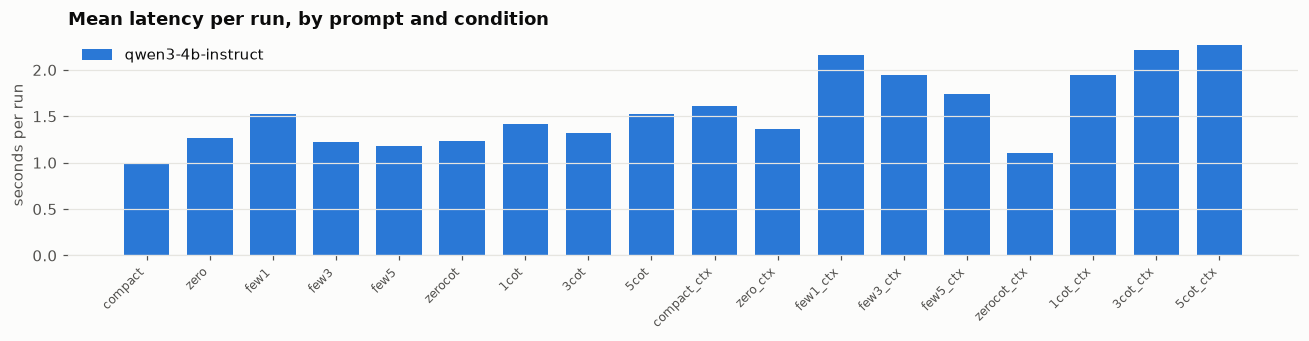

In [21]:
lat = runs.groupby(["model", "variant"]).latency_s.mean().unstack().reindex(index=models_present)
lat = lat[[c for c in order_cols if c in lat.columns]]
fig, ax = plt.subplots(figsize=(12, 3.2))
x = np.arange(len(lat.columns))
w = 0.8 / max(1, len(lat.index))
for i, m in enumerate(lat.index):
    ax.bar(x + i * w - 0.4 + w / 2, lat.loc[m], width=w * 0.9, color=[BLUE, ORANGE, AQUA][i % 3], label=m)
ax.set_xticks(x, lat.columns, rotation=45, ha="right", fontsize=8); ax.grid(axis="x", visible=False)
ax.set_ylabel("seconds per run"); ax.legend(ncol=3, loc="upper left")
ax.set_title("Mean latency per run, by prompt and condition")
fig.tight_layout(); plt.show()

**Cost is small; the energy numbers are not usable yet.**

- Qwen ran 3,240 runs in about 1.4 hours on an Apple M4 (1.6 s per run on average), with 1.30 M input and 0.09 M output tokens (28 output tokens per run).
- That is 0.11 correct hidden values per 1,000 tokens.
- The 19 Wh of energy is a CodeCarbon CPU/RAM estimate: CodeCarbon cannot measure the Apple GPU that Ollama runs on, so it undercounts, and it is not comparable with the EcoLogits figures of the paper. Energy for the paper should be measured on a machine with an NVIDIA GPU.

## 5. Discussion

**The pipeline and the scoring are correct, and the run is usable.**

- **Correctness checks passed:** the 36 tasks and their difficulty match the published ones exactly; the published scoring reproduces 5 of the 6 Table 3 rows; format compliance is ~100%; a hand check of scored answers agrees with the scorer.
- **One scoring bug was found and fixed during this analysis:** a latitude or longitude asked alone could not be compared by the paper's rule and was counted wrong; the standard scoring now compares it within 0.1° (and `location` as a coordinate pair).

**Findings worth carrying into the new paper:**

1. A 4B open model on a laptop is not usable for this task as is: F1 0.07–0.15, with half of the hidden values confidently wrong.
2. The published metric (precision = 1, abstentions ignored, unasked and echoed properties counted) overstates every model and makes a weak model look competitive; report correct / wrong / abstained and the standard F1.
3. Three issues in the published results need checking: the Claude Sonnet row of Table 3, the 4-airport coverage of the Gemini with-context runs, and the GPT-5 Mini with-context request file.
4. Whether G identifies the entity matters more than the popularity-based difficulty, and some "easy" properties are not real-world facts.

**Next steps:** run larger open models (e.g. `qwen3:14b` with `think: false`, `mistral-small3.2:24b`, `gemma3:27b`) on a GPU machine, where energy can also be measured; then Strategy B (search) on the same tasks, which should mainly reduce the wrong answers.

## 6. Limitations

- **One model**, quantized to 4 bits (Q4_K_M); results for its full-precision version may differ.
- **36 tasks from 9 airports**: the 95% intervals are wide (±0.05–0.1 F1), and tasks of the same airport are correlated, so the intervals are optimistic.
- **With-context inputs are reconstructed** with the published procedure and a fixed seed; the published slices were not saved (only a partial Gemini batch file exists), so the with-context comparison with the paper is approximate.
- **The paper's tolerance is kept**: it is generous (a runway length 12% off counts as correct) and unit-blind (feet against metres counts as wrong); this affects all models alike.
- **Ground-truth quirks**: `runwaysLength` and `runwaysWidth` are means over an airport's runways, in feet; `distCity` is in metres; 10 hidden properties have no ground truth and are not scored.
- **Representative answer**: the paper's vote over non-empty answers (text: most frequent, numbers: mean), not the medoid of EVALUATION_SPEC.
- **Energy** is a CPU/RAM estimate on a Mac (see 4.7).